# 03. Clasificación con el texto de las reseñas

Se repite el procedimiento del cuaderno 02 usando como variables explicativas las palabras del comentario. El problema cambia de "¿el cliente quedará insatisfecho?" a "¿el comentario corresponde a un cliente insatisfecho?", que es el caso de uso de un sistema que prioriza la atención de reseñas negativas.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import ConfusionMatrixDisplay

from src.datos import cargar_pedidos
from src.modelos import (SEMILLA, comparar_modelos, buscar_hiperparametros, evaluar_finales,
                         recall_por_grupo)
from src.graficos import configurar_estilo, guardar, AZUL, NARANJA, GRIS

configurar_estilo()
df = cargar_pedidos("../data/raw")

## 1. Pedidos con comentario

In [2]:
com = df.dropna(subset=["review_comment_message"]).reset_index(drop=True)
print(f"Pedidos con comentario: {len(com):,} ({com['insatisfecho'].mean():.1%} insatisfechos)")
com[["review_comment_message", "review_score"]].head()

Pedidos con comentario: 40,775 (35.3% insatisfechos)


,review_comment_message,review_score
0,"Não testei o produto ainda, mas ele veio corre...",4
1,Muito bom o produto.,4
2,O produto foi exatamente o que eu esperava e e...,5
3,fiquei triste por n ter me atendido.,2
4,Aguardando retorno da loja,1


## 2. Representación del texto

Se usa una bolsa de palabras binaria: cada palabra del vocabulario es una columna que vale 1 si aparece en el comentario y 0 si no. Se conservan las palabras presentes en al menos 5 comentarios del entrenamiento (`min_df=5`) para descartar errores de digitación. El vocabulario se construye solo con el conjunto de entrenamiento.

In [3]:
ejemplo = ["produto chegou quebrado", "produto excelente chegou rápido", "não chegou"]
v = CountVectorizer(binary=True).fit(ejemplo)
pd.DataFrame(v.transform(ejemplo).toarray(), columns=v.get_feature_names_out(), index=ejemplo)

,chegou,excelente,não,produto,quebrado,rápido
produto chegou quebrado,1,0,0,1,1,0
produto excelente chegou rápido,1,1,0,1,0,1
não chegou,1,0,1,0,0,0


In [4]:
T_ent, T_prueba, y_ent, y_prueba, grupo_ent, grupo_prueba = train_test_split(
    com["review_comment_message"], com["insatisfecho"].values, com["estado_entrega"].values,
    test_size=0.2, random_state=SEMILLA, stratify=com["insatisfecho"].values)

vectorizador = CountVectorizer(binary=True, min_df=5)
X_ent = vectorizador.fit_transform(T_ent)
X_prueba = vectorizador.transform(T_prueba)
print("Entrenamiento:", X_ent.shape, " Prueba:", X_prueba.shape)

Entrenamiento: (32620, 3219)  Prueba: (8155, 3219)


No se aplica submuestreo: la proporción de insatisfechos (35 %) es menos desbalanceada que en el cuaderno 02. Tampoco se estandariza, porque todas las variables son binarias.

## 3. Modelos con parámetros por defecto

In [5]:
base, _ = comparar_modelos(X_ent, y_ent, X_prueba, y_prueba)
base

,f1_satisfecho,f1_insatisfecho
modelo,,
Decision Tree,0.882,0.776
Random Forest,0.917,0.848
KNN,0.890,0.769
Regresión logística,0.921,0.850
MLP,0.921,0.853


## 4. Búsqueda de hiperparámetros

In [6]:
busqueda, mejores = buscar_hiperparametros(X_ent, y_ent)
busqueda.to_csv("../reports/busqueda_texto.csv", index=False)
busqueda.pivot_table(index=["modelo", "valor"], values=["f1_satisfecho", "f1_insatisfecho"], sort=False)

f1_satisfecho  f1_insatisfecho
modelo              valor                                    
Decision Tree       3                  0.865            0.694
                    5                  0.870            0.721
                    10                 0.879            0.749
                    20                 0.884            0.770
                    40                 0.890            0.784
                    None               0.880            0.774
Random Forest       10                 0.907            0.820
                    50                 0.916            0.844
                    100                0.917            0.848
                    200                0.918            0.849
KNN                 1                  0.872            0.740
                    3                  0.890            0.766
                    5                  0.890            0.759
                    11                 0.885            0.736
                    21                 0.876            0.696
                    51                 0.861            0.629
Regresión logística 0.01               0.899            0.791
                    0.1                0.919            0.841
                    1                  0.920            0.846
                    10                 0.911            0.828
MLP                 (10,)              0.920            0.847
                    (50,)              0.922            0.847
                    (100,)             0.921            0.849
                    (100, 50)          0.922            0.853

In [7]:
mejores

{'Decision Tree': 40,
 'Random Forest': 200,
 'KNN': 3,
 'Regresión logística': 1,
 'MLP': (100, 50)}

A diferencia del cuaderno 02, en KNN aumentar el número de vecinos empeora el resultado: los comentarios más cercanos son informativos, pero al ampliar el vecindario se incorporan comentarios no relacionados, en su mayoría de clientes satisfechos.

## 5. Evaluación en el conjunto de prueba

In [8]:
finales, matrices, modelos = evaluar_finales(mejores, X_ent, y_ent, X_prueba, y_prueba)
finales.to_csv("../reports/metricas_texto.csv")
finales

,hiperparametro,f1_satisfecho,f1_insatisfecho,supera_umbral
modelo,,,,
Decision Tree,max_depth=40,0.890,0.784,True
Random Forest,n_estimators=200,0.918,0.851,True
KNN,n_neighbors=3,0.890,0.774,True
Regresión logística,C=1,0.921,0.850,True
MLP,"hidden_layer_sizes=(100, 50)",0.918,0.855,True


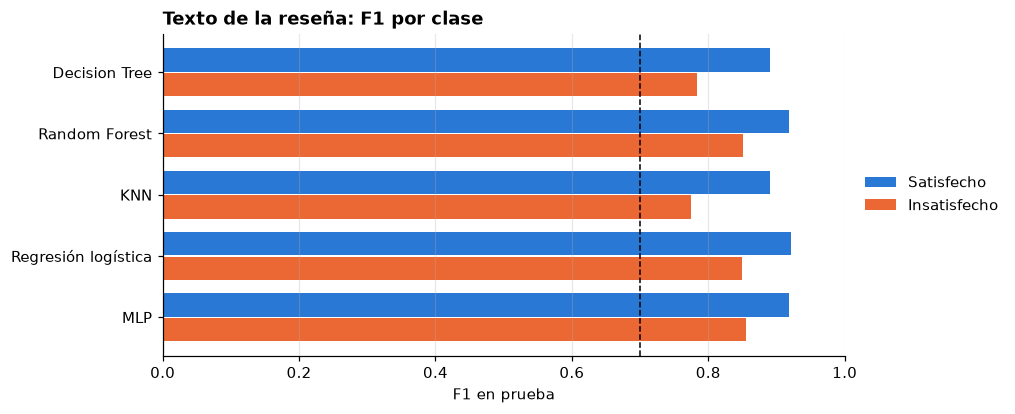

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
pos = np.arange(len(finales))
ax.barh(pos - 0.2, finales["f1_satisfecho"], height=0.38, color=AZUL, label="Satisfecho")
ax.barh(pos + 0.2, finales["f1_insatisfecho"], height=0.38, color=NARANJA, label="Insatisfecho")
ax.axvline(0.7, color="black", ls="--", lw=1)
ax.set_yticks(pos, finales.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F1 en prueba")
ax.set_title("Texto de la reseña: F1 por clase")
ax.grid(axis="x", alpha=0.3); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
guardar(fig, "f1_texto")
plt.show()

Mejor modelo: MLP hidden_layer_sizes=(100, 50)


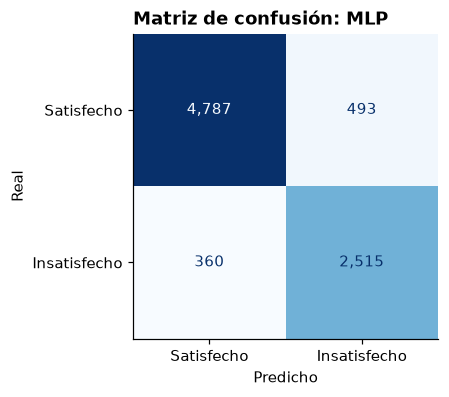

Insatisfechos detectados (recall): 87.5%
Precisión en la clase insatisfecho: 83.6%


In [10]:
mejor = finales[["f1_satisfecho", "f1_insatisfecho"]].min(axis=1).idxmax()
print("Mejor modelo:", mejor, finales.loc[mejor, "hiperparametro"])

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(matrices[mejor], display_labels=["Satisfecho", "Insatisfecho"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
ax.set_title(f"Matriz de confusión: {mejor}")
guardar(fig, "matriz_confusion_texto")
plt.show()

vn, fp, fn, vp = matrices[mejor].ravel()
print(f"Insatisfechos detectados (recall): {vp / (vp + fn):.1%}")
print(f"Precisión en la clase insatisfecho: {vp / (vp + fp):.1%}")

## 6. Análisis por estado de entrega

Se repite el análisis del cuaderno 02 para verificar si el modelo de texto identifica también a los insatisfechos que recibieron el pedido a tiempo.

In [11]:
pred = modelos[mejor].predict(X_prueba)
recall_texto = recall_por_grupo(y_prueba, pred, grupo_prueba)
recall_texto.to_csv("../reports/recall_estado_entrega_texto.csv")

recall_pedido = pd.read_csv("../reports/recall_estado_entrega_pedido.csv", index_col=0)
comparacion = pd.DataFrame({"Variables del pedido": recall_pedido["recall"],
                            "Texto de la reseña": recall_texto["recall"]})
comparacion

,Variables del pedido,Texto de la reseña
grupo,,
A tiempo,0.221,0.838
No entregado,0.993,0.951
Tarde,0.933,0.937


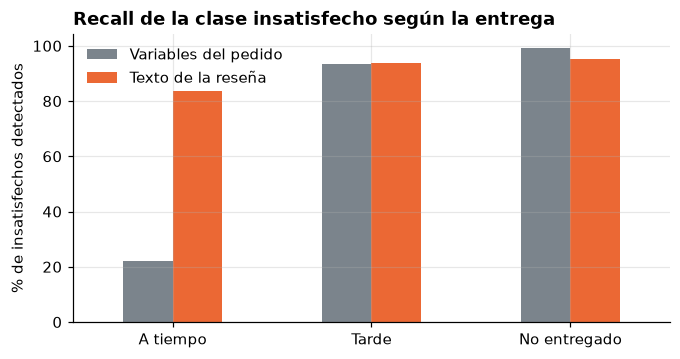

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
comparacion.loc[["A tiempo", "Tarde", "No entregado"]].mul(100).plot.bar(ax=ax, color=[GRIS, NARANJA], rot=0)
ax.set_ylabel("% de insatisfechos detectados")
ax.set_xlabel("")
ax.set_title("Recall de la clase insatisfecho según la entrega")
ax.legend(frameon=False)
guardar(fig, "recall_comparacion")
plt.show()

Los dos conjuntos de prueba no son idénticos (el del cuaderno 02 incluye pedidos sin comentario), pero la comparación por grupo muestra la diferencia principal: con texto, el modelo detecta a los insatisfechos que recibieron a tiempo.

## 7. Interpretación

La regresión logística asigna un peso a cada palabra: los positivos aumentan la probabilidad de insatisfacción y los negativos la reducen.

In [13]:
logistica = LogisticRegression(max_iter=2000).fit(X_ent, y_ent)
pesos = pd.Series(logistica.coef_[0], index=vectorizador.get_feature_names_out()).sort_values()
pd.DataFrame({"hacia insatisfecho": pesos.tail(15)[::-1].index, "peso": pesos.tail(15)[::-1].values.round(2),
              "hacia satisfecho": pesos.head(15).index, "peso ": pesos.head(15).values.round(2)})

,hacia insatisfecho,peso,hacia satisfecho,peso
0,péssima,2.90,excelente,-2.74
1,atrasada,2.58,ótimo,-2.52
2,porcaria,2.43,otimo,-2.43
3,péssimo,2.39,amei,-2.38
4,pessima,2.25,adorei,-2.35
5,entrar,2.22,show,-2.33
6,insatisfeita,2.13,parabéns,-2.22
7,baixa,2.11,maravilhoso,-2.16
8,ruim,2.11,surpreendeu,-2.13
9,inferior,2.07,testei,-2.06


In [14]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(X_ent, y_ent)
print(export_text(arbol, feature_names=list(vectorizador.get_feature_names_out())))

|--- não <= 0.50
|   |--- comprei <= 0.50
|   |   |--- nao <= 0.50
|   |   |   |--- class: 0
|   |   |--- nao >  0.50
|   |   |   |--- class: 1
|   |--- comprei >  0.50
|   |   |--- prazo <= 0.50
|   |   |   |--- class: 1
|   |   |--- prazo >  0.50
|   |   |   |--- class: 0
|--- não >  0.50
|   |--- antes <= 0.50
|   |   |--- mas <= 0.50
|   |   |   |--- class: 1
|   |   |--- mas >  0.50
|   |   |   |--- class: 1
|   |--- antes >  0.50
|   |   |--- do <= 0.50
|   |   |   |--- class: 1
|   |   |--- do >  0.50
|   |   |   |--- class: 0



## 8. Comentarios nuevos

In [15]:
nuevos = [
    "Chegou antes do prazo, produto excelente. Recomendo!",
    "Ainda não recebi meu pedido e ninguém responde.",
    "O produto veio quebrado.",
    "Produto bom, mas a entrega demorou muito.",
    "Veio diferente do anunciado.",
    "Tudo certo, recebi conforme o anúncio.",
]
prob = modelos[mejor].predict_proba(vectorizador.transform(nuevos))[:, 1]
pd.DataFrame({"comentario": nuevos, "prob_insatisfecho": prob.round(3),
              "clase": np.where(prob >= 0.5, "Insatisfecho", "Satisfecho")})

,comentario,prob_insatisfecho,clase
0,"Chegou antes do prazo, produto excelente. Reco...",0.002,Satisfecho
1,Ainda não recebi meu pedido e ninguém responde.,0.989,Insatisfecho
2,O produto veio quebrado.,0.960,Insatisfecho
3,"Produto bom, mas a entrega demorou muito.",0.634,Insatisfecho
4,Veio diferente do anunciado.,0.846,Insatisfecho
5,"Tudo certo, recebi conforme o anúncio.",0.038,Satisfecho


El cuarto comentario combina una valoración positiva y una negativa. La bolsa de palabras no considera el orden ni la relación entre palabras, por lo que la probabilidad queda cerca del límite de decisión.

## 9. Conclusiones

| Enfoque | Mejor modelo | F1 satisfecho | F1 insatisfecho | Supera 0,7 |
|---|---|---|---|---|
| Variables del pedido (cuaderno 02) | Decision Tree, `max_depth=5` | 0,870 | 0,510 | No |
| Texto de la reseña (cuaderno 03) | MLP, `hidden_layer_sizes=(100, 50)` | 0,918 | 0,855 | Sí |

1. Con el texto de la reseña los cinco modelos superan el umbral de 0,7 en ambas clases. El mejor es la red neuronal MLP.
2. La mejora se explica por el cambio en las variables explicativas, no por el algoritmo: con los mismos modelos y el mismo procedimiento, el F1 de la clase insatisfecho pasa de cerca de 0,5 a más de 0,8.
3. El modelo de texto identifica a los insatisfechos cuyo pedido llegó a tiempo, que el enfoque anterior no detectaba.
4. Limitaciones: solo el 41 % de los clientes deja comentario y la representación no captura el orden de las palabras.

### Recomendaciones

- Integrar el clasificador en la recepción de reseñas para priorizar la atención de los comentarios negativos.
- Monitorear los pedidos en riesgo de retraso y notificar al cliente antes de la fecha estimada.
- Reforzar la capacidad logística en temporadas de alta demanda (noviembre, febrero-marzo).
- Informar al cliente cuando un pedido tenga varios vendedores y llegará en envíos separados.
- Hacer seguimiento a vendedores con despachos tardíos y a productos con quejas recurrentes de calidad o diferencias con el anuncio.